# Hands-On Data Lab Implementation
### Data Science Fundamentals – Practical Lab (Task 2)

**Author:** Dhanireddy Venu Madhav Reddy  
**Tools:** Python · Jupyter Notebook · NumPy · Pandas · Matplotlib · Seaborn · Scikit-learn

---

## Purpose of this notebook
This notebook is a complete, reproducible **hands-on data lab**. It sets up the Data Science environment, practises NumPy and Pandas, cleans a deliberately messy dataset, builds visualizations, performs a basic statistical analysis, and documents the observations from every exercise.

| # | Lab objective | Where it is done |
|---|---|---|
| 1 | Set up the Data Science environment | Section 1 |
| 2 | Work with data using Pandas & NumPy | Sections 2, 3 and 5 |
| 3 | Perform data cleaning | Section 4 |
| 4 | Create data visualizations | Section 6 |
| 5 | Perform basic data analysis | Section 7 |
| 6 | Complete & document practical exercises | Every section (code → output → observation); summary in Sections 8–9 |

## About the dataset
The lab uses an **online-retail dataset made of three related tables**:

| File | Rows describe | Key columns |
|---|---|---|
| `orders.csv` | One customer order | order_id, order_date, customer_id, product_id, quantity, discount_pct, payment_method, order_status, delivery_days, rating |
| `customers.csv` | One customer | customer_id, city, region, segment, age, signup_date |
| `products.csv` | One product | product_id, product_name, category, unit_price (in Rs) |

> **Important – the data is synthetic.** No public dataset can be downloaded in this environment, so the files were generated with a fixed random seed by `src/generate_data.py`. Data-quality problems (missing values, duplicates, inconsistent text, wrong data types, impossible values) were injected on purpose so the cleaning exercises are realistic. Patterns found in this data illustrate the techniques; they are **not real-world findings**.

## How the notebook is organized
Every exercise follows the same pattern: **task → code → output → observation**.

---
# 1. Set Up the Data Science Environment

### Exercise 1.1 – Install and configure the tools
These are the steps used to prepare the environment (run in a terminal, from the project folder).

```bash
# 1) Install Python 3.10 or newer from https://www.python.org/downloads/  (tick "Add Python to PATH")
python --version

# 2) Create and activate an isolated virtual environment
python -m venv .venv
.venv\Scripts\activate            # Windows
source .venv/bin/activate         # macOS / Linux

# 3) Install the libraries (NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn, SciPy, Jupyter)
pip install -r requirements.txt

# 4) Start Jupyter Notebook and open notebooks/Hands_On_Data_Lab.ipynb
jupyter notebook
```

Why a virtual environment? It keeps this project's library versions separate from other projects, so the analysis can be reproduced later on any computer.

### Exercise 1.2 – Verify the installation
The next cell prints the Python version and the version of every library used in this lab. If any line says *not installed*, install that package and re-run the cell.

In [1]:
import sys, platform
from importlib.metadata import version

print("Python        :", sys.version.split()[0], f"({platform.system()})")
for pkg in ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "scipy"]:
    try:
        print(f"{pkg:<14}:", version(pkg))
    except Exception:
        print(f"{pkg:<14}: not installed")

Python        : 3.12.3 (Linux)
numpy         : 2.4.4
pandas        : 3.0.2
matplotlib    : 3.10.8
seaborn       : 0.13.2
scikit-learn  : 1.8.0
scipy         : 1.17.1


### Exercise 1.3 – Import libraries and configure the notebook
Standard aliases (`np`, `pd`, `plt`, `sns`) are used, a **random seed** makes every random result repeatable, and all file paths are *relative* to the project root so the notebook runs on any machine.

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Seaborn 0.13 + Matplotlib 3.10 print a harmless deprecation notice for box plots; hide only that message
warnings.filterwarnings("ignore", message="vert: bool will be deprecated")

SEED = 42
rng = np.random.default_rng(SEED)            # one seeded generator -> reproducible results

# ---- display and plotting settings
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# ---- project paths (works whether the notebook is started from the project root or from /notebooks)
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
RAW_DIR, PROC_DIR, FIG_DIR = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "outputs" / "figures"
for folder in (PROC_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current Matplotlib figure into outputs/figures."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print("Project folder :", ROOT.name)
print("Raw data files :", sorted(p.name for p in RAW_DIR.glob("*.csv")))

Project folder : lab
Raw data files : ['customers.csv', 'orders.csv', 'products.csv']


**Observation.** All six libraries import without errors and the three raw CSV files are found, so the environment is ready.

> **Note on Pandas versions.** This notebook was executed with Pandas 3.x, where text columns show the dtype `str`. In Pandas 2.x the same columns show `object`. The code works the same in both.

---
# 2. NumPy Practice

NumPy provides fast, memory-efficient **n-dimensional arrays** and vectorized math. Pandas is built on top of it, so these skills carry over directly.

### Exercise 2.1 – Creating arrays and inspecting their properties

In [3]:
a = np.array([12, 18, 25, 31, 40])          # from a Python list
b = np.arange(0, 10, 2)                     # start, stop (excluded), step
c = np.linspace(0, 1, 5)                    # 5 evenly spaced numbers from 0 to 1
z = np.zeros((2, 3))                        # 2 rows x 3 columns of 0.0
o = np.ones((2, 3), dtype=int)              # 2 rows x 3 columns of 1

for name, arr in [("a", a), ("b", b), ("c", c), ("z", z), ("o", o)]:
    print(f"{name}: shape={arr.shape}, dtype={arr.dtype}, ndim={arr.ndim}")
print()
print("a =", a)
print("b =", b)
print("c =", c)

a: shape=(5,), dtype=int64, ndim=1
b: shape=(5,), dtype=int64, ndim=1
c: shape=(5,), dtype=float64, ndim=1
z: shape=(2, 3), dtype=float64, ndim=2
o: shape=(2, 3), dtype=int64, ndim=2

a = [12 18 25 31 40]
b = [0 2 4 6 8]
c = [0.   0.25 0.5  0.75 1.  ]


**Observation.** Every array has a fixed `shape`, `dtype` and `ndim`. `arange` excludes its stop value (so `b` ends at 8), while `linspace` includes both ends. Integer inputs give an integer dtype and any decimal input gives `float64`.

### Exercise 2.2 – Vectorized arithmetic and broadcasting
*Task: compute gross and net revenue for five orders **without writing a loop**.*

In [4]:
unit_price = np.array([899, 2499, 18999, 249, 599])      # Rs per unit
quantity   = np.array([2, 1, 1, 5, 3])
discount   = np.array([10, 0, 5, 20, 15]) / 100         # percent -> fraction

gross = unit_price * quantity                            # element-wise multiplication
net   = gross * (1 - discount)                           # element-wise, whole array at once
print("Gross revenue :", gross)
print("Net revenue   :", net.round(2))
print("Total net     : Rs", f"{net.sum():,.2f}")

# Broadcasting: a (3,1) column and a (3,) row combine into a (3,3) table
base_price = np.array([[100], [200], [300]])             # shape (3, 1)
rates      = np.array([0.05, 0.10, 0.15])                # shape (3,)
print("\nPrice after each discount rate (rows = base price, columns = rate):")
print(base_price * (1 - rates))

Gross revenue : [ 1798  2499 18999  1245  1797]
Net revenue   : [ 1618.2   2499.   18049.05   996.    1527.45]
Total net     : Rs 24,689.70

Price after each discount rate (rows = base price, columns = rate):
[[ 95.  90.  85.]
 [190. 180. 170.]
 [285. 270. 255.]]


**Observation.** Arithmetic on arrays is applied element by element, so the whole calculation is two lines. In the broadcasting example NumPy stretched the (3,1) and (3,) arrays into a (3,3) table automatically: each row is one base price and each column one discount rate.

### Exercise 2.3 – Why vectorization matters (speed comparison)

In [5]:
import time

big = rng.integers(100, 5000, size=1_000_000)

t0 = time.perf_counter()
loop_result = [x * 0.9 for x in big.tolist()]            # pure-Python loop
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
vec_result = big * 0.9                                   # NumPy vectorized
t_vec = time.perf_counter() - t0

print(f"Python loop : {t_loop*1000:8.1f} ms")
print(f"NumPy       : {t_vec*1000:8.1f} ms")
print(f"NumPy was about {t_loop / t_vec:.0f}x faster for 1,000,000 values")
print("Same answer?  ", np.allclose(loop_result, vec_result))

Python loop :    255.8 ms
NumPy       :      3.5 ms
NumPy was about 72x faster for 1,000,000 values
Same answer?   True


**Observation.** For one million numbers the NumPy version was about **72x faster** than the Python loop, and both gave identical results. (Exact timings differ from computer to computer and run to run, but NumPy is consistently far faster.) This is why Data Science code avoids Python loops over data.

### Exercise 2.4 – Indexing, slicing, boolean masks and axis operations
*Scenario: monthly units sold in 4 regions over 6 months.*

In [6]:
sales = rng.integers(50, 500, size=(4, 6))                 # 4 regions x 6 months
print(sales, "\n")

print("Row totals (per region)   :", sales.sum(axis=1))
print("Column means (per month)  :", sales.mean(axis=0).round(1))
print("First 2 regions, last 3 months:\n", sales[:2, -3:])

mask = sales > 300                                         # boolean mask
print("\nCells above 300 :", mask.sum(), "of", sales.size)
print("Those values     :", sales[mask])
print("Labels, region 0 :", np.where(sales[0] >= 300, "High", "Low"))
print("Best month index per region:", sales.argmax(axis=1))
print("Five largest values:", np.sort(sales.ravel())[::-1][:5])

[[418 212 384  72 338 488]
 [219 307 382 399 382 211]
 [263 224 268 178  91 394]
 [231 243  65  76 328 443]] 

Row totals (per region)   : [1912 1900 1418 1386]
Column means (per month)  : [282.8 246.5 274.8 181.2 284.8 384. ]
First 2 regions, last 3 months:
 [[ 72 338 488]
 [399 382 211]]

Cells above 300 : 11 of 24
Those values     : [418 384 338 488 307 382 399 382 394 328 443]
Labels, region 0 : ['High' 'Low' 'High' 'Low' 'High' 'High']
Best month index per region: [5 3 5 5]
Five largest values: [488 443 418 399 394]


**Observation.** `axis=1` collapses columns (one result per row/region) and `axis=0` collapses rows (one result per month). A boolean mask such as `sales > 300` selects values by condition, and `np.where` builds a labelled array in a single step, the same idea Pandas uses for filtering and for creating new columns.

### Exercise 2.5 – Statistics, normalization and correlation with NumPy

In [7]:
delivery = rng.normal(loc=5, scale=1.5, size=200).round(2)      # simulated delivery times (days)
rating   = 100 - 8 * delivery + rng.normal(0, 4, size=200)      # a score that falls as delivery time grows

print(f"Mean {delivery.mean():.2f} | Median {np.median(delivery):.2f} | "
      f"Std (population) {delivery.std():.2f} | Std (sample) {delivery.std(ddof=1):.2f}")
print("Percentiles 25/50/75:", np.percentile(delivery, [25, 50, 75]).round(2))

z_scores = (delivery - delivery.mean()) / delivery.std()                       # standardization
min_max  = (delivery - delivery.min()) / (delivery.max() - delivery.min())     # scale to 0-1
print(f"\nZ-scores  -> mean {z_scores.mean():.4f}, std {z_scores.std():.4f}")
print(f"Min-max   -> min {min_max.min():.1f}, max {min_max.max():.1f}")
print("Correlation (delivery vs rating):", np.corrcoef(delivery, rating)[0, 1].round(3))

Mean 4.89 | Median 4.80 | Std (population) 1.66 | Std (sample) 1.66
Percentiles 25/50/75: [3.84 4.8  5.94]

Z-scores  -> mean -0.0000, std 1.0000
Min-max   -> min 0.0, max 1.0
Correlation (delivery vs rating): -0.955


**Observation.** After z-score standardization the data has mean 0 and standard deviation 1; min-max scaling squeezes values into the 0 to 1 range. The sample standard deviation (`ddof=1`, 1.66) is slightly larger than the population one (1.66). The correlation of **-0.955** is strongly negative, as expected because the second variable was built to fall when delivery time rises.

---
# 3. Loading Data and Pandas Fundamentals

### Exercise 3.1 – Load the datasets
`pd.read_csv()` loads each CSV file into a **DataFrame**. The raw orders table is stored as `orders_raw` and is never modified, so the original data always stays available for comparison.

In [8]:
orders_raw    = pd.read_csv(RAW_DIR / "orders.csv")
customers_raw = pd.read_csv(RAW_DIR / "customers.csv")
products      = pd.read_csv(RAW_DIR / "products.csv")

for name, d in [("orders", orders_raw), ("customers", customers_raw), ("products", products)]:
    print(f"{name:<10} rows = {d.shape[0]:>4}   columns = {d.shape[1]}")

orders_raw.head()

orders     rows =  536   columns = 10
customers  rows =  120   columns = 6
products   rows =   20   columns = 4


,order_id,order_date,customer_id,product_id,quantity,discount_pct,payment_method,order_status,delivery_days,rating
0,ORD0118,2025-05-04,C999,P01,2.00,5%,Debit Card,Delivered,6.0,4.00
1,ORD0133,2025-06-09,C026,P09,1.00,0%,UPI,Delivered,3.0,5.00
2,ORD0155,2025-12-25,C032,P11,1.00,20%,Cash,Delivered,8.0,4.00
3,ORD0246,2025-01-05,C035,P01,1.00,10%,UPI,Delivered,5.0,5.00
4,ORD0085,2025-03-15,C091,P19,4.00,NaN,Cash,Delivered,2.0,5.00


### Exercise 3.2 – Inspect structure, types and summary statistics

In [9]:
orders_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 536 entries, 0 to 535
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        536 non-null    str    
 1   order_date      536 non-null    str    
 2   customer_id     536 non-null    str    
 3   product_id      536 non-null    str    
 4   quantity        509 non-null    float64
 5   discount_pct    520 non-null    str    
 6   payment_method  536 non-null    str    
 7   order_status    536 non-null    str    
 8   delivery_days   519 non-null    str    
 9   rating          505 non-null    float64
dtypes: float64(2), str(8)
memory usage: 42.0 KB


In [10]:
display(orders_raw.describe().T)
display(customers_raw.describe().T)

,count,mean,std,min,25%,50%,75%,max
quantity,509.00,2.43,1.77,-2.00,1.00,2.00,3.00,8.00
rating,505.00,4.51,0.69,0.00,4.00,5.00,5.00,9.00


,count,mean,std,min,25%,50%,75%,max
age,111.00,42.98,25.20,-5.00,29.00,42.00,55.00,260.00


**Observation.**
- `orders_raw` has **536 rows**, but the dtype of `delivery_days` and `discount_pct` is text (`str`), although they should be numeric. Text hides numbers from `describe()`, which is why those two columns are missing from the table above.
- `quantity` has a minimum of **-2** and `rating` has a maximum of **9**, both impossible (quantity must be positive and ratings range from 1 to 5).
- `customers_raw` shows ages from **-5** to **260**, which are impossible too.

These problems are fixed in Section 4.

### Exercise 3.3 – Selecting data (columns, `loc`, `iloc`)

In [11]:
print("One column (a Series):")
print(orders_raw["order_id"].head(3).to_string(), "\n")

print("Several columns (a DataFrame):")
display(orders_raw[["order_id", "product_id", "quantity"]].head(3))

print("loc  - select by LABEL (rows 0 to 2 inclusive, chosen columns):")
display(orders_raw.loc[0:2, ["order_id", "rating"]])

print("iloc - select by POSITION (first 3 rows, first 3 columns):")
display(orders_raw.iloc[0:3, 0:3])

One column (a Series):
0    ORD0118
1    ORD0133
2    ORD0155 

Several columns (a DataFrame):


,order_id,product_id,quantity
0,ORD0118,P01,2.00
1,ORD0133,P09,1.00
2,ORD0155,P11,1.00


loc  - select by LABEL (rows 0 to 2 inclusive, chosen columns):


,order_id,rating
0,ORD0118,4.00
1,ORD0133,5.00
2,ORD0155,4.00


iloc - select by POSITION (first 3 rows, first 3 columns):


,order_id,order_date,customer_id
0,ORD0118,2025-05-04,C999
1,ORD0133,2025-06-09,C026
2,ORD0155,2025-12-25,C032


**Observation.** `df["col"]` returns a Series, `df[["a","b"]]` returns a DataFrame, `loc` uses labels (the end label is *included*), and `iloc` uses integer positions (the end position is *excluded*).

### Exercise 3.4 – Filtering rows

In [12]:
big_orders = orders_raw[orders_raw["quantity"] >= 5]
print("Orders with quantity >= 5                 :", len(big_orders))

upi_multi = orders_raw[(orders_raw["payment_method"] == "UPI") & (orders_raw["quantity"] >= 3)]
print("UPI orders with quantity >= 3 (& = AND)   :", len(upi_multi))

two_products = orders_raw[orders_raw["product_id"].isin(["P04", "P05"])]
print("Orders for products P04 or P05 (isin)     :", len(two_products))

good = orders_raw.query("rating >= 4 and quantity > 1")
print("Rating >= 4 and quantity > 1 (query)      :", len(good))

print("\nA filtering trap: orders paid by UPI")
print("  exact match  == 'UPI'                  :", (orders_raw["payment_method"] == "UPI").sum())
print("  after strip + lowercase, == 'upi'      :", orders_raw["payment_method"].str.strip().str.lower().eq("upi").sum())

Orders with quantity >= 5                 : 55
UPI orders with quantity >= 3 (& = AND)   : 60
Orders for products P04 or P05 (isin)     : 78
Rating >= 4 and quantity > 1 (query)      : 290

A filtering trap: orders paid by UPI
  exact match  == 'UPI'                  : 192
  after strip + lowercase, == 'upi'      : 205


In [13]:
orders_raw["payment_method"].value_counts()

payment_method
UPI              192
Credit Card      146
Debit Card       107
Cash              58
upi                8
 UPI               5
 Debit Card        5
CREDIT CARD        4
credit card        3
 Cash              3
cash               2
 Credit Card       1
CASH               1
debit card         1
Name: count, dtype: int64

**Observation.** Conditions are combined with `&` (and), `|` (or) and `~` (not), each wrapped in parentheses. The last test reveals a **data-quality trap**: the exact filter finds only **192** UPI orders, but **205** really exist, because the same label was typed as `UPI`, `upi` and ` UPI `. The `value_counts()` above shows **14 different labels for only 4 payment methods**. Filtering uncleaned text silently gives wrong answers.

### Exercise 3.5 – Sorting

In [14]:
print("Highest quantities first (missing values are placed last):")
display(orders_raw.sort_values("quantity", ascending=False)[["order_id", "product_id", "quantity", "rating"]].head(5))

print("Sort by rating (high to low), ties broken by quantity (high to low):")
display(orders_raw.sort_values(["rating", "quantity"], ascending=[False, False])[["order_id", "rating", "quantity"]].head(5))

print("nlargest is a shortcut for 'sort then head':")
display(orders_raw.nlargest(3, "quantity")[["order_id", "quantity"]])

Highest quantities first (missing values are placed last):


,order_id,product_id,quantity,rating
84,ORD0454,P11,8.00,5.00
464,ORD0035,P12,8.00,5.00
450,ORD0402,P12,8.00,5.00
281,ORD0335,P14,8.00,3.00
267,ORD0287,P12,8.00,NaN


Sort by rating (high to low), ties broken by quantity (high to low):


,order_id,rating,quantity
54,ORD0079,9.00,2.00
219,ORD0142,7.00,2.00
6,ORD0007,5.00,8.00
84,ORD0454,5.00,8.00
87,ORD0007,5.00,8.00


nlargest is a shortcut for 'sort then head':


,order_id,quantity
6,ORD0007,8.00
84,ORD0454,8.00
87,ORD0007,8.00


**Observation.** `sort_values` accepts several columns with a separate direction for each, and puts missing values at the end by default. `nlargest` / `nsmallest` are shorter and faster when only the top few rows are needed. Notice that the same `order_id` (for example ORD0007) can appear twice in the raw output: these are the duplicate records removed in Section 4.

---
# 4. Data Cleaning

Real data is rarely analysis-ready. This section follows a systematic process:

**audit → remove duplicates → standardize text → fix data types → handle invalid values → handle missing values → verify → save.**

Each decision is explained, because *how* a problem is fixed changes the results.

### Exercise 4.1 – Audit: find the data-quality problems

In [15]:
def audit(df, name):
    """Return a per-column quality table (type, missing count, missing %, unique values)."""
    print(f"{name}: {df.shape[0]} rows x {df.shape[1]} columns | duplicate rows: {df.duplicated().sum()}")
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(1),
        "unique": df.nunique(),
    })

display(audit(orders_raw, "ORDERS (raw)"))
display(audit(customers_raw, "CUSTOMERS (raw)"))

ORDERS (raw): 536 rows x 10 columns | duplicate rows: 16


,dtype,missing,missing_%,unique
order_id,str,0,0.00,520
order_date,str,0,0.00,255
customer_id,str,0,0.00,119
product_id,str,0,0.00,20
quantity,float64,27,5.00,11
discount_pct,str,16,3.00,6
payment_method,str,0,0.00,14
order_status,str,0,0.00,8
delivery_days,str,17,3.20,12
rating,float64,31,5.80,7


CUSTOMERS (raw): 120 rows x 6 columns | duplicate rows: 0


,dtype,missing,missing_%,unique
customer_id,str,0,0.00,120
city,str,0,0.00,18
segment,str,0,0.00,3
age,float64,9,7.50,44
region,str,0,0.00,4
signup_date,str,0,0.00,114


In [16]:
# Problems that a missing-value count cannot reveal
date_parsed   = pd.to_datetime(orders_raw["order_date"], format="%Y-%m-%d", errors="coerce")
delivery_num  = pd.to_numeric(orders_raw["delivery_days"], errors="coerce")
discount_num  = pd.to_numeric(orders_raw["discount_pct"].str.rstrip("%"), errors="coerce")

issues = pd.Series({
    "Orders: exact duplicate rows": orders_raw.duplicated().sum(),
    "Orders: invalid / unparseable dates": date_parsed.isna().sum() - orders_raw["order_date"].isna().sum(),
    "Orders: quantity missing": orders_raw["quantity"].isna().sum(),
    "Orders: quantity zero or negative": (orders_raw["quantity"] <= 0).sum(),
    "Orders: discount stored as text, e.g. '10%'": orders_raw["discount_pct"].notna().sum(),
    "Orders: discount missing or non-numeric": discount_num.isna().sum(),
    "Orders: delivery_days missing": orders_raw["delivery_days"].isna().sum(),
    "Orders: delivery_days is text (e.g. 'TBD')": delivery_num.isna().sum() - orders_raw["delivery_days"].isna().sum(),
    "Orders: delivery_days above 30 days": (delivery_num > 30).sum(),
    "Orders: rating missing (not rated)": orders_raw["rating"].isna().sum(),
    "Orders: rating outside 1-5": (~orders_raw["rating"].dropna().between(1, 5)).sum(),
    "Orders: payment labels (should be 4)": orders_raw["payment_method"].nunique(),
    "Orders: status labels (should be 3)": orders_raw["order_status"].nunique(),
    "Orders: customer_id not in customers table": (~orders_raw["customer_id"].isin(customers_raw["customer_id"])).sum(),
    "Customers: age missing": customers_raw["age"].isna().sum(),
    "Customers: age outside 18-100": (~customers_raw["age"].dropna().between(18, 100)).sum(),
    "Customers: city labels (should be 9)": customers_raw["city"].nunique(),
}, name="count").to_frame()
issues

,count
Orders: exact duplicate rows,16
Orders: invalid / unparseable dates,3
Orders: quantity missing,27
Orders: quantity zero or negative,4
"Orders: discount stored as text, e.g. '10%'",520
Orders: discount missing or non-numeric,21
Orders: delivery_days missing,17
Orders: delivery_days is text (e.g. 'TBD'),6
Orders: delivery_days above 30 days,3
Orders: rating missing (not rated),31


**Observation.** The audit found problems in every category of data quality: **duplicates** (16 rows), **missing values** (quantity, discount, delivery days, rating, age), **inconsistent text** (14 payment labels for 4 methods, 18 city labels for 9 cities), **incorrect data types** (numbers stored as text such as `'10%'` and `'TBD'`, dates stored as strings), **invalid values** (zero or negative quantities, ratings outside 1-5, impossible ages, deliveries over 30 days, unparseable dates) and a **referential problem** (orders whose customer is not in the customer table).

Work now continues on **copies** (`orders`, `customers`) so the raw data is never overwritten.

### Exercise 4.2 – Remove duplicate records

In [17]:
orders    = orders_raw.copy()
customers = customers_raw.copy()

dup_mask = orders.duplicated(keep=False)            # keep=False marks BOTH copies of a duplicate
print("Rows that belong to a duplicate pair:", dup_mask.sum())
display(orders[dup_mask].sort_values("order_id").head(6))

rows_before = len(orders)
orders = orders.drop_duplicates().reset_index(drop=True)
print(f"\nRows before: {rows_before} | after drop_duplicates(): {len(orders)} | removed: {rows_before - len(orders)}")
print("Order IDs that still repeat:", orders["order_id"].duplicated().sum())

Rows that belong to a duplicate pair: 32


,order_id,order_date,customer_id,product_id,quantity,discount_pct,payment_method,order_status,delivery_days,rating
6,ORD0007,2025-07-24,C089,P13,8.00,20%,Credit Card,Delivered,4.0,5.00
87,ORD0007,2025-07-24,C089,P13,8.00,20%,Credit Card,Delivered,4.0,5.00
20,ORD0011,2025-07-27,C091,P04,2.00,10%,Cash,Delivered,4.0,5.00
254,ORD0011,2025-07-27,C091,P04,2.00,10%,Cash,Delivered,4.0,5.00
16,ORD0091,2025-06-05,C047,P10,1.00,15%,Credit Card,Delivered,NaN,5.00
73,ORD0091,2025-06-05,C047,P10,1.00,15%,Credit Card,Delivered,NaN,5.00



Rows before: 536 | after drop_duplicates(): 520 | removed: 16
Order IDs that still repeat: 0


**Observation.** Each duplicate appeared as an exact copy of an existing row. After `drop_duplicates()` every `order_id` is unique again (**520 orders** remain). Leaving duplicates in would have double-counted revenue and orders.

### Exercise 4.3 – Standardize inconsistent text
Strategy: remove leading/trailing spaces, convert to one letter case, then map variants to one official label.

In [18]:
print("BEFORE -> payment labels:", orders["payment_method"].nunique(),
      "| status labels:", orders["order_status"].nunique(),
      "| city labels:", customers["city"].nunique())

pay_map = {"upi": "UPI", "credit card": "Credit Card", "debit card": "Debit Card", "cash": "Cash"}
orders["payment_method"] = orders["payment_method"].str.strip().str.lower().map(pay_map)
orders["order_status"]   = orders["order_status"].str.strip().str.title()

customers["city"] = customers["city"].str.strip().str.title().replace({"Bangalore": "Bengaluru"})  # same city, two names

print("AFTER  -> payment labels:", orders["payment_method"].nunique(),
      "| status labels:", orders["order_status"].nunique(),
      "| city labels:", customers["city"].nunique())
print("Unmapped payment values:", orders["payment_method"].isna().sum())
print("Each city belongs to exactly one region:", (customers.groupby("city")["region"].nunique() == 1).all())
print()
print(orders["payment_method"].value_counts().to_string())
print()
print(orders["order_status"].value_counts().to_string())

BEFORE -> payment labels: 14 | status labels: 8 | city labels: 18
AFTER  -> payment labels: 4 | status labels: 3 | city labels: 9
Unmapped payment values: 0
Each city belongs to exactly one region: True

payment_method
UPI            199
Credit Card    150
Debit Card     108
Cash            63

order_status
Delivered    465
Returned      38
Cancelled     17


**Observation.** Payment labels dropped to **4**, status labels to **3** and city labels to **9**. Using `.map()` with a dictionary is safer than blind replacement: any label missing from the dictionary would become `NaN` and be noticed (here there are none). The check that every city maps to a single region confirms the standardization did not merge different places.

### Exercise 4.4 – Fix incorrect data types

In [19]:
print("BEFORE:", orders[["order_date", "discount_pct", "delivery_days"]].dtypes.astype(str).to_dict())

orders["order_date"]    = pd.to_datetime(orders["order_date"], format="%Y-%m-%d", errors="coerce")   # bad dates -> NaT
orders["discount_pct"]  = pd.to_numeric(orders["discount_pct"].str.rstrip("%"), errors="coerce")     # '10%' -> 10.0
orders["delivery_days"] = pd.to_numeric(orders["delivery_days"], errors="coerce")                    # 'TBD' -> NaN
orders["payment_method"] = orders["payment_method"].astype("category")
orders["order_status"]   = orders["order_status"].astype("category")
customers["signup_date"] = pd.to_datetime(customers["signup_date"], format="%Y-%m-%d")

print("AFTER :", orders[["order_date", "discount_pct", "delivery_days", "payment_method"]].dtypes.astype(str).to_dict())
print("Dates that could not be parsed (now NaT):", orders["order_date"].isna().sum())
print("\nOriginal text of the unparseable dates:")
display(orders_raw.loc[date_parsed.isna(), ["order_id", "order_date"]])

BEFORE: {'order_date': 'str', 'discount_pct': 'str', 'delivery_days': 'str'}
AFTER : {'order_date': 'datetime64[us]', 'discount_pct': 'float64', 'delivery_days': 'float64', 'payment_method': 'category'}
Dates that could not be parsed (now NaT): 3

Original text of the unparseable dates:


,order_id,order_date
18,ORD0212,2025-02-30
72,ORD0069,not available
114,ORD0366,2025-13-45


**Observation.** The text columns are now proper types: dates are `datetime64`, and discount and delivery time are numeric so they can be averaged. `errors="coerce"` converts values that cannot be parsed (such as `'TBD'`, `'unknown'` or the impossible date `2025-02-30`) into `NaN`/`NaT` instead of crashing, turning hidden bad values into countable missing values. The repeated labels were stored as `category`, which saves memory and prevents typos.

### Exercise 4.5 – Handle invalid values and outliers
Impossible values are converted to missing (`NaN`) first, so that they can be handled with the other missing values.

In [20]:
# Rule-based validation (domain knowledge defines what is impossible)
bad_qty    = orders["quantity"] <= 0
bad_rating = orders["rating"].notna() & ~orders["rating"].between(1, 5)
bad_age    = customers["age"].notna() & ~customers["age"].between(18, 100)
print(f"Invalid quantity (<= 0): {bad_qty.sum()} | Invalid rating (not 1-5): {bad_rating.sum()} | Invalid age: {bad_age.sum()}")
orders.loc[bad_qty, "quantity"]     = np.nan
orders.loc[bad_rating, "rating"]    = np.nan
customers.loc[bad_age, "age"]       = np.nan

# Outliers in delivery_days: compare a statistical rule (IQR) with a domain rule
q1, q3 = orders["delivery_days"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
print(f"\nQ1 = {q1:.0f}, Q3 = {q3:.0f}, IQR = {iqr:.0f}  ->  IQR upper fence = {upper_fence:.1f} days")
iqr_flagged = int((orders["delivery_days"] > upper_fence).sum())
print("Values above the IQR fence      :", iqr_flagged)
print("Values above 30 days (domain rule):", (orders["delivery_days"] > 30).sum())
display(orders.loc[orders["delivery_days"] > 30, ["order_id", "delivery_days"]])

Invalid quantity (<= 0): 4 | Invalid rating (not 1-5): 3 | Invalid age: 2

Q1 = 4, Q3 = 6, IQR = 2  ->  IQR upper fence = 9.0 days
Values above the IQR fence      : 3
Values above 30 days (domain rule): 3


,order_id,delivery_days
10,ORD0105,75.00
260,ORD0287,90.00
330,ORD0439,60.00


In [21]:
too_slow = orders["delivery_days"] > 30        # a retail delivery over 30 days is treated as a data-entry error
orders.loc[too_slow, "delivery_days"] = np.nan
print("Delivery times set to missing:", too_slow.sum())
print("Maximum delivery time now    :", orders["delivery_days"].max())

Delivery times set to missing: 3
Maximum delivery time now    : 9.0


**Observation.** Impossible quantities, ratings and ages were converted to missing values (to be handled in the next step). For delivery times two rules were compared: the **IQR rule** (upper fence 9.0 days) flags **3** values and the **domain rule** (more than 30 days is implausible for a retail delivery) flags **3**: the extreme entries of 60, 75 and 90 days. In this dataset both rules agree, which gives extra confidence in the decision. 
In general, **statistical rules only suggest candidates; domain knowledge makes the final decision**, because a value that is unusual is not necessarily wrong.

### Exercise 4.6 – Handle missing values (four different strategies)
There is no single correct way to treat missing data: the right choice depends on the column and on how the data will be used. Four strategies are applied here, each with its reason.

| Column | Strategy | Reason |
|---|---|---|
| `order_date` | **Drop** the rows | An order without a date cannot be placed in time; very few rows are affected |
| `quantity` | **Impute** with the median quantity of the same product category | Needed to compute revenue; the median is robust, and a category-specific value is more realistic than one global value |
| `discount_pct` | **Fill with 0** | Assumption: no recorded discount means no discount was given (to be confirmed with the data owner) |
| `delivery_days`, `rating` | **Leave as missing** | Inventing a delivery time or a customer's opinion would fabricate information; analyses simply skip missing values |

In [22]:
cols = ["order_date", "quantity", "discount_pct", "delivery_days", "rating"]
print("Missing values BEFORE handling:")
display(orders[cols].isna().sum().to_frame("missing").T)

# (a) DROP rows whose date could not be parsed
orders = orders.dropna(subset=["order_date"]).reset_index(drop=True)

# (b) IMPUTE quantity with the median of its product category
category = orders["product_id"].map(products.set_index("product_id")["category"])
qty_median_by_category = orders.groupby(category)["quantity"].median()
fill_values = orders.groupby(category)["quantity"].transform("median").round()
orders["quantity"] = orders["quantity"].fillna(fill_values).astype(int)
print("Median quantity used for imputation, by category:")
print(qty_median_by_category.to_string())

# (c) FILL discount with a constant
orders["discount_pct"] = orders["discount_pct"].fillna(0)

# (d) delivery_days and rating are deliberately left as NaN
print("\nMissing values AFTER handling:")
display(orders[cols].isna().sum().to_frame("missing").T)

Missing values BEFORE handling:


,order_date,quantity,discount_pct,delivery_days,rating
missing,3,30,20,25,33


Median quantity used for imputation, by category:
product_id
Clothing      3.00
Electronics   1.00
Furniture     1.00
Stationery    4.00

Missing values AFTER handling:


,order_date,quantity,discount_pct,delivery_days,rating
missing,0,0,0,25,33


**Observation.** Three rows with unusable dates were dropped (**517 orders** remain), every missing `quantity` was filled with a sensible category median and the missing discounts were set to 0. `delivery_days` (25 missing) and `rating` (33 missing) keep their gaps on purpose; a missing rating usually means the customer did not rate, which is information in itself.

**Trade-off to remember:** imputation keeps the sample size but slightly shrinks the natural variation of the data, so it should always be documented.

### Exercise 4.7 – Verify, compare and save the clean data

In [23]:
orders_clean, customers_clean = orders.copy(), customers.copy()

# Automatic validation checks (the cell stops with an error if any rule is broken)
assert orders_clean["order_id"].is_unique
assert (orders_clean["quantity"] > 0).all()
assert orders_clean["rating"].dropna().between(1, 5).all()
assert orders_clean["delivery_days"].dropna().between(0, 30).all()
assert orders_clean["discount_pct"].between(0, 100).all()
assert orders_clean["order_date"].notna().all()
assert orders_clean["payment_method"].nunique() == 4 and orders_clean["order_status"].nunique() == 3
assert customers_clean["age"].dropna().between(18, 100).all() and customers_clean["city"].nunique() == 9
print("All validation checks passed.\n")

summary = pd.DataFrame({
    "Raw orders":   [len(orders_raw), orders_raw.duplicated().sum(), orders_raw.isna().sum().sum(),
                     orders_raw["payment_method"].nunique(), orders_raw["order_status"].nunique()],
    "Clean orders": [len(orders_clean), orders_clean.duplicated().sum(), orders_clean.isna().sum().sum(),
                     orders_clean["payment_method"].nunique(), orders_clean["order_status"].nunique()],
}, index=["Rows", "Duplicate rows", "Missing cells (all columns)", "Payment-method labels", "Order-status labels"])
display(summary)

print("Data types after cleaning:")
print(orders_clean.dtypes.astype(str).to_string())

orders_clean.to_csv(PROC_DIR / "orders_clean.csv", index=False)
customers_clean.to_csv(PROC_DIR / "customers_clean.csv", index=False)
print("\nSaved:", [p.name for p in sorted(PROC_DIR.glob("*.csv"))])

All validation checks passed.



,Raw orders,Clean orders
Rows,536,517
Duplicate rows,16,0
Missing cells (all columns),91,58
Payment-method labels,14,4
Order-status labels,8,3


Data types after cleaning:
order_id                     str
order_date        datetime64[us]
customer_id                  str
product_id                   str
quantity                   int64
discount_pct             float64
payment_method          category
order_status            category
delivery_days            float64
rating                   float64

Saved: ['customers_clean.csv', 'orders_clean.csv']


**Observation.** All eight validation checks pass, so the cleaned data satisfies the rules defined in this section. Rows fell from **536 to 517** (16 duplicates and 3 undated orders removed), payment and status labels were reduced to their true counts, and the remaining **58** missing cells are the deliberate gaps in `delivery_days` and `rating`. Saving the clean tables to `data/processed/` means later work can start from verified data instead of repeating the cleaning.

---
# 5. Merging, Transformation and Aggregation with Pandas

### Exercise 5.1 – Merge the three tables
Orders are linked to products (by `product_id`) and to customers (by `customer_id`). A **left join** keeps every order. `validate="m:1"` makes Pandas check that each order matches at most one product/customer, and `indicator=True` reports which rows found a match.

In [24]:
df = (orders_clean
      .merge(products, on="product_id", how="left", validate="m:1")
      .merge(customers_clean[["customer_id", "city", "region", "segment", "age"]],
             on="customer_id", how="left", validate="m:1", indicator=True))

print("Merged table:", df.shape)
print(df["_merge"].value_counts().to_string())

inner = orders_clean.merge(customers_clean, on="customer_id", how="inner")
print(f"\nAn INNER join would keep {len(inner)} rows and silently lose {len(orders_clean) - len(inner)} orders.")
display(df.loc[df["_merge"] == "left_only", ["order_id", "customer_id", "product_name", "region"]].head())

for col in ["city", "region", "segment"]:             # orders from unknown customers get an explicit label
    df[col] = df[col].fillna("Unknown")
df = df.drop(columns="_merge")

Merged table: (517, 18)
_merge
both          510
left_only       7
right_only      0

An INNER join would keep 510 rows and silently lose 7 orders.


,order_id,customer_id,product_name,region
0,ORD0118,C999,Wireless Mouse,NaN
45,ORD0010,C999,Office Chair,NaN
143,ORD0305,C999,Hoodie,NaN
192,ORD0109,C999,Gel Pens (10),NaN
213,ORD0068,C999,Bookshelf,NaN


**Observation.** The merge attached product details (name, category, price) and customer details (city, region, segment, age) to each order. **7 orders belong to customer `C999`, who does not exist in the customer table.** An inner join would have dropped them without any warning, which would understate sales; the left join keeps them and they are labelled `Unknown` so they stay visible in every report.

### Exercise 5.2 – Create new columns (transformation)

In [25]:
# Revenue columns
df["gross_revenue"] = df["quantity"] * df["unit_price"]
df["revenue"]       = df["gross_revenue"] * (1 - df["discount_pct"] / 100)
df["net_revenue"]   = np.where(df["order_status"] == "Delivered", df["revenue"], 0.0)   # only delivered orders count as sales

# Date parts
df["month"]   = df["order_date"].dt.month
df["quarter"] = "Q" + df["order_date"].dt.quarter.astype(str)
df["weekday"] = df["order_date"].dt.day_name()

# Binning numeric columns into labelled groups
df["price_band"] = pd.cut(df["unit_price"], bins=[0, 500, 2000, 10000, np.inf],
                          labels=["Budget (<=500)", "Mid (501-2000)", "Premium (2001-10000)", "Luxury (>10000)"])
df["delivery_speed"] = pd.cut(df["delivery_days"], bins=[0, 3, 5, 7, np.inf],
                              labels=["Express (<=3)", "Standard (4-5)", "Slow (6-7)", "Very slow (8+)"])
df["is_problem_order"] = df["order_status"].isin(["Returned", "Cancelled"])

display(df[["order_id", "quantity", "unit_price", "discount_pct", "gross_revenue", "revenue", "net_revenue",
            "order_status", "month", "price_band", "delivery_speed"]].head(6))
print("Gross revenue (all orders)   : Rs", f"{df['gross_revenue'].sum():,.0f}")
print("Revenue after discounts      : Rs", f"{df['revenue'].sum():,.0f}")
print("Net revenue (delivered only) : Rs", f"{df['net_revenue'].sum():,.0f}")

,order_id,quantity,unit_price,discount_pct,gross_revenue,revenue,net_revenue,order_status,month,price_band,delivery_speed
0,ORD0118,2,899,5.00,1798,"1,708.10","1,708.10",Delivered,5,Mid (501-2000),Slow (6-7)
1,ORD0133,1,4599,0.00,4599,"4,599.00","4,599.00",Delivered,6,Premium (2001-10000),Express (<=3)
2,ORD0155,1,249,20.00,249,199.20,199.20,Delivered,12,Budget (<=500),Very slow (8+)
3,ORD0246,1,899,10.00,899,809.10,809.10,Delivered,1,Mid (501-2000),Standard (4-5)
4,ORD0085,4,2999,0.00,11996,"11,996.00","11,996.00",Delivered,3,Premium (2001-10000),Express (<=3)
5,ORD0347,2,18999,0.00,37998,"37,998.00","37,998.00",Delivered,10,Luxury (>10000),Standard (4-5)


Gross revenue (all orders)   : Rs 6,034,316
Revenue after discounts      : Rs 5,563,666
Net revenue (delivered only) : Rs 4,981,217


**Observation.** Four kinds of transformation were used: **arithmetic** (revenue after discount), **conditional logic** (`np.where` counts only *Delivered* orders as sales), **date extraction** (`.dt` accessor) and **binning** (`pd.cut` turns continuous prices and delivery times into labelled groups). Discounts reduced revenue from Rs 6,034,316 to Rs 5,563,666 (**7.8%** lower) and excluding returned or cancelled orders brings net revenue to Rs 4,981,217. Using the right definition of revenue matters: the three totals differ noticeably.

### Exercise 5.3 – Group and aggregate

In [26]:
# 1) By category: several statistics at once with named aggregation
cat_summary = (df.groupby("category")
                 .agg(orders=("order_id", "count"),
                      units=("quantity", "sum"),
                      net_revenue=("net_revenue", "sum"),
                      avg_order_value=("revenue", "mean"),
                      avg_rating=("rating", "mean"))
                 .sort_values("net_revenue", ascending=False))
cat_summary["revenue_share_%"] = cat_summary["net_revenue"] / cat_summary["net_revenue"].sum() * 100
display(cat_summary)

# 2) By region
region_summary = (df.groupby("region")
                    .agg(orders=("order_id", "count"),
                         net_revenue=("net_revenue", "sum"),
                         avg_delivery_days=("delivery_days", "mean"),
                         avg_rating=("rating", "mean"),
                         problem_rate_pct=("is_problem_order", lambda s: s.mean() * 100))
                    .sort_values("avg_delivery_days"))
display(region_summary)

,orders,units,net_revenue,avg_order_value,avg_rating,revenue_share_%
category,,,,,,
Electronics,164,239,"3,598,352.50","24,399.71",4.50,72.24
Clothing,128,348,"610,467.40","5,252.17",4.54,12.26
Furniture,100,143,"605,722.50","7,079.43",4.46,12.16
Stationery,125,554,"166,674.50","1,455.14",4.50,3.35


,orders,net_revenue,avg_delivery_days,avg_rating,problem_rate_pct
region,,,,,
South,189,"2,099,504.75",4.05,4.70,7.41
West,122,"1,026,118.50",4.72,4.57,14.75
Unknown,7,"17,552.40",5.00,4.43,14.29
North,154,"1,350,298.40",5.31,4.38,11.69
East,45,"487,742.85",6.64,3.91,8.89


In [27]:
# 3) Pivot table: net revenue (Rs lakh) by region x category, with totals
pivot = df.pivot_table(values="net_revenue", index="region", columns="category",
                       aggfunc="sum", fill_value=0, margins=True, margins_name="Total") / 1e5
display(pivot)

# 4) Cross-tabulation: row percentages of order status within each payment method
display(pd.crosstab(df["payment_method"], df["order_status"], normalize="index").mul(100).round(1))

# 5) Monthly trend with a rolling mean and a running total
monthly = df.groupby("month").agg(orders=("order_id", "count"), net_revenue=("net_revenue", "sum"))
monthly["rolling_3m"]  = monthly["net_revenue"].rolling(3).mean()
monthly["cumulative"]  = monthly["net_revenue"].cumsum()
display(monthly)

# 6) Top 5 products by net revenue
top_products = df.groupby("product_name")["net_revenue"].sum().nlargest(5)
print("Top 5 products by net revenue (Rs):")
print(top_products.round(0).to_string())

category,Clothing,Electronics,Furniture,Stationery,Total
region,,,,,
East,0.55,3.81,0.29,0.23,4.88
North,1.61,9.50,1.86,0.53,13.50
South,2.29,15.36,2.70,0.65,21.00
Unknown,0.02,0.02,0.14,0.00,0.18
West,1.63,7.29,1.07,0.27,10.26
Total,6.10,35.98,6.06,1.67,49.81


order_status,Cancelled,Delivered,Returned
payment_method,,,
Cash,1.60,95.20,3.20
Credit Card,3.30,89.30,7.30
Debit Card,3.70,85.00,11.20
UPI,3.60,89.80,6.60


,orders,net_revenue,rolling_3m,cumulative
month,,,,
1,46,"560,285.10",NaN,"560,285.10"
2,31,"237,481.45",NaN,"797,766.55"
3,37,"182,012.60","326,593.05","979,779.15"
4,29,"306,305.60","241,933.22","1,286,084.75"
5,47,"235,180.50","241,166.23","1,521,265.25"
6,33,"372,848.00","304,778.03","1,894,113.25"
7,30,"245,874.15","284,634.22","2,139,987.40"
8,38,"263,458.35","294,060.17","2,403,445.75"
9,46,"845,603.25","451,645.25","3,249,049.00"


Top 5 products by net revenue (Rs):
product_name
Laptop        2,422,706.00
Smartphone      717,212.00
Study Desk      242,222.00
Smart Watch     210,774.00
Sneakers        198,984.00


**Observation.**
- **Category:** **Electronics** earns the most net revenue (**72.2%** of the total). It also has the most orders (164), but its revenue share is far larger than its share of orders (31.7%) because its items are expensive.
- **Region:** among the known regions, average delivery time is shortest in **South** (4.1 days) and longest in **East** (6.6 days). Orders with an `Unknown` region (customer `C999`) are shown separately instead of being hidden.
- **Time:** the busiest month by net revenue is **month 9**; the 3-month rolling mean smooths the month-to-month noise and the cumulative column gives the running total (Rs 4,981,217 by December).
- **Best seller:** **Laptop** is the top product by net revenue (Rs 2,422,706).

### Exercise 5.4 – NumPy functions on Pandas columns
Pandas columns work directly with NumPy: `np.log1p` for skewed data, `np.select` for multi-way conditions, and z-scores for standardization.

In [28]:
df["log_revenue"] = np.log1p(df["revenue"])                                             # log(1 + x) compresses large values
df["delivery_z"]  = (df["delivery_days"] - df["delivery_days"].mean()) / df["delivery_days"].std()
df["order_size"]  = np.select([df["revenue"] >= 20000, df["revenue"] >= 5000], ["Large", "Medium"], default="Small")

print(f"Skewness of revenue      : {df['revenue'].skew():.2f}")
print(f"Skewness of log(revenue) : {df['log_revenue'].skew():.2f}")
print("\nOrders by size (revenue >= 20,000 = Large; >= 5,000 = Medium):")
print(df["order_size"].value_counts().to_string())
print("\nDeliveries more than 2 standard deviations from the mean (|z| > 2):", int((df["delivery_z"].abs() > 2).sum()))

Skewness of revenue      : 3.38
Skewness of log(revenue) : 0.36

Orders by size (revenue >= 20,000 = Large; >= 5,000 = Medium):
order_size
Small     297
Medium    165
Large      55

Deliveries more than 2 standard deviations from the mean (|z| > 2): 35


**Observation.** Revenue is strongly right-skewed (skewness **3.38**) because a few expensive orders are much larger than the typical one; after the log transform the skewness falls to **0.36**, which makes the data far easier to plot and model. `np.select` created a three-level order-size column in one statement, and the z-score identifies **35** unusually fast or slow deliveries.

---
# 6. Data Visualization (Matplotlib and Seaborn)

Each chart is chosen to match the question it answers, saved to `outputs/figures/`, and followed by an observation.

| Question | Chart type |
|---|---|
| Compare totals across categories | Bar chart |
| How does a quantity change over time? | Line chart |
| What is the shape of a distribution? | Histogram |
| How do two numeric variables relate? | Scatter plot, correlation heat map |
| How does a numeric variable differ across groups? | Box plot |
| How are parts of a whole composed? | Stacked bar chart |

Amounts are shown in **Rs lakh** (1 lakh = 100,000).

In [29]:
def lakh(x):
    return f"Rs {x / 1e5:,.2f} lakh"

palette = sns.color_palette("deep")
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

### Chart 1 – Bar chart (Matplotlib): net revenue by category

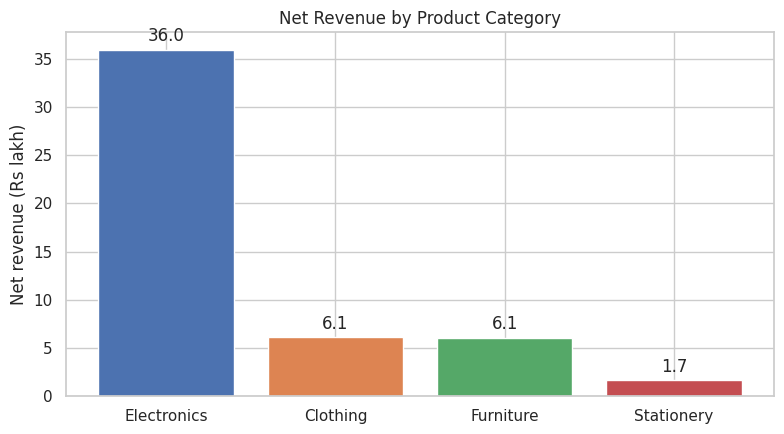

In [30]:
fig, ax = plt.subplots(figsize=(8, 4.5))
vals = cat_summary["net_revenue"] / 1e5
bars = ax.bar(vals.index, vals.values, color=palette[: len(vals)])
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set(title="Net Revenue by Product Category", xlabel="", ylabel="Net revenue (Rs lakh)")
save_fig("01_bar_revenue_by_category")
plt.show()

**Observation.** **Electronics** clearly leads with Rs 35.98 lakh, followed by Clothing and Furniture; **Stationery** contributes the least (Rs 1.67 lakh). Data labels on the bars let the reader see exact values without reading the axis.

### Chart 2 – Count plot (Seaborn): orders by payment method

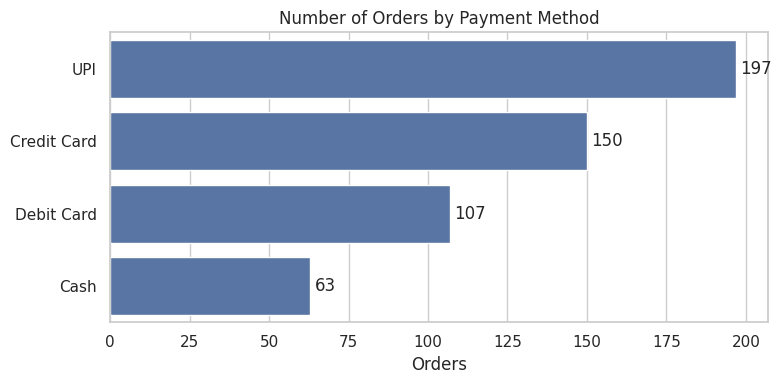

In [31]:
order_pay = df["payment_method"].value_counts().index
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=df, y="payment_method", order=order_pay, color=palette[0], ax=ax)
ax.bar_label(ax.containers[0], padding=3)
ax.set(title="Number of Orders by Payment Method", xlabel="Orders", ylabel="")
save_fig("02_count_payment_method")
plt.show()

**Observation.** **UPI** is the most used payment method with 197 orders (**38.1%** of all orders); **Cash** is the least used. A horizontal layout keeps the labels readable.

### Chart 3 – Line chart (Matplotlib): monthly net revenue with a rolling average

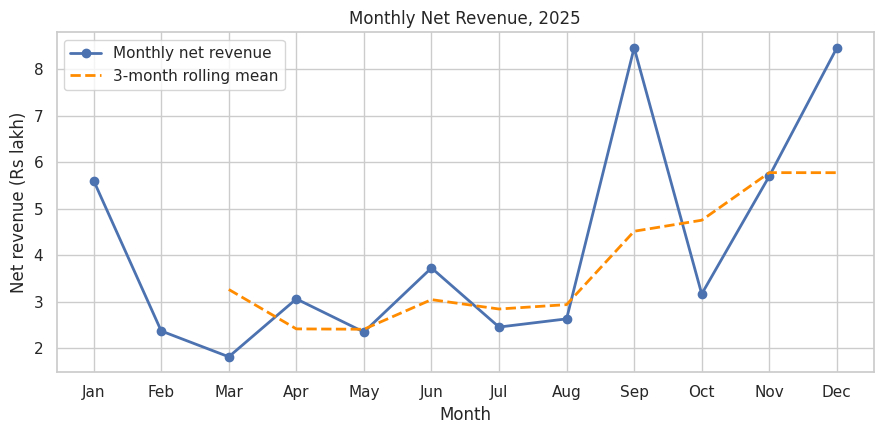

In [32]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(monthly.index, monthly["net_revenue"] / 1e5, marker="o", linewidth=2, label="Monthly net revenue")
ax.plot(monthly.index, monthly["rolling_3m"] / 1e5, linestyle="--", linewidth=2, color="darkorange", label="3-month rolling mean")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.set(title="Monthly Net Revenue, 2025", xlabel="Month", ylabel="Net revenue (Rs lakh)")
ax.legend()
save_fig("03_line_monthly_revenue")
plt.show()

**Observation.** Monthly revenue is volatile: the two highest months are **Sep** (Rs 8.46 lakh) and **Dec** (Rs 8.45 lakh) and the lowest is **Mar** (Rs 1.82 lakh). Because a single Laptop order is worth about Rs 55,000, a handful of expensive orders can move a whole month, which is why the line is jagged. The **number of orders** is steadier and peaks in **Nov** (70 orders). The dashed 3-month rolling mean smooths the noise: it rises from Rs 2.94 lakh (August) to Rs 5.77 lakh (December). The last quarter (Oct to Dec) accounts for **34.8%** of the year's net revenue, above the 25% an even spread would give.

### Chart 4 – Histogram (Seaborn): distribution of delivery time

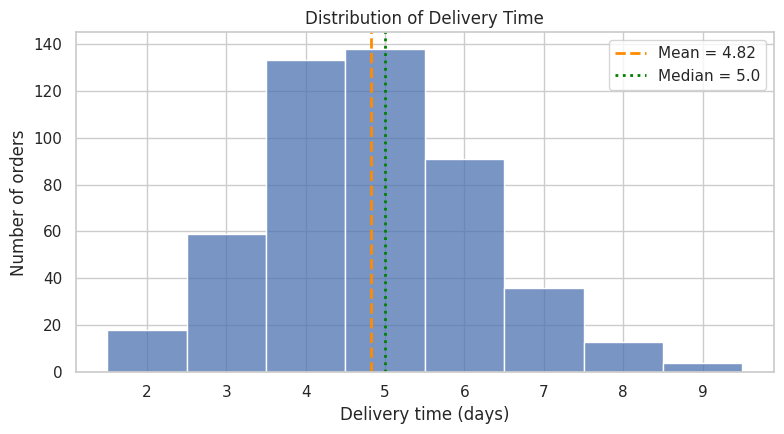

In [33]:
d = df["delivery_days"].dropna()
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(d, discrete=True, color=palette[0], ax=ax)
ax.axvline(d.mean(), color="darkorange", linestyle="--", linewidth=2, label=f"Mean = {d.mean():.2f}")
ax.axvline(d.median(), color="green", linestyle=":", linewidth=2, label=f"Median = {d.median():.1f}")
ax.set(title="Distribution of Delivery Time", xlabel="Delivery time (days)", ylabel="Number of orders")
ax.legend()
save_fig("04_hist_delivery_days")
plt.show()

**Observation.** The most common delivery time is **5 days**, the mean is **4.82** and the median **5.0** days. They are close, so the distribution is nearly symmetric (skewness 0.31); **89.2%** of deliveries arrive within 6 days. The bars are `discrete` because delivery time is recorded in whole days.

### Chart 5 – Histograms side by side: raw vs log-transformed revenue

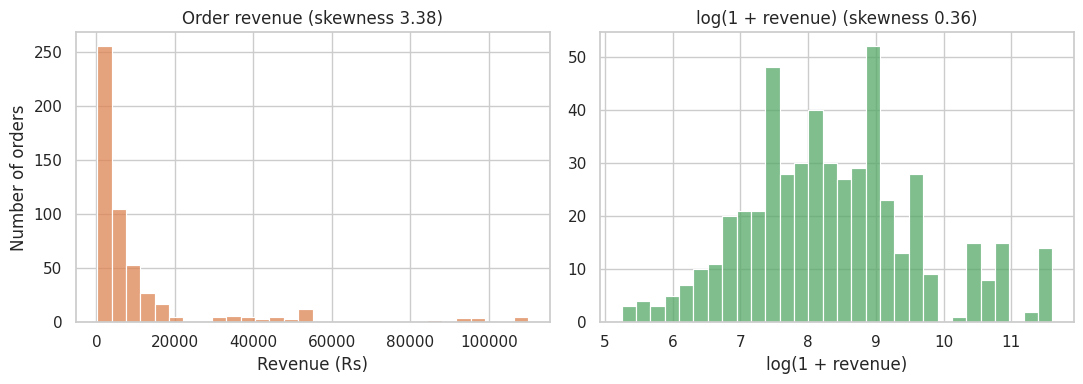

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["revenue"], bins=30, color=palette[1], ax=axes[0])
axes[0].set(title=f"Order revenue (skewness {df['revenue'].skew():.2f})", xlabel="Revenue (Rs)", ylabel="Number of orders")
sns.histplot(df["log_revenue"], bins=30, color=palette[2], ax=axes[1])
axes[1].set(title=f"log(1 + revenue) (skewness {df['log_revenue'].skew():.2f})", xlabel="log(1 + revenue)", ylabel="")
save_fig("05_hist_revenue_raw_vs_log")
plt.show()

**Observation.** The raw revenue histogram is squeezed against the left edge with a long tail to the right (skewness **3.38**): most orders are small but a few are very large. After the log transform the shape is much more balanced (skewness **0.36**), showing that a transform can reveal structure hidden in skewed data.

### Chart 6 – Scatter plot (Seaborn): delivery time vs rating
Ratings are whole numbers, so a little random "jitter" is added to the points to stop them overlapping. A trend line is fitted with `np.polyfit`.

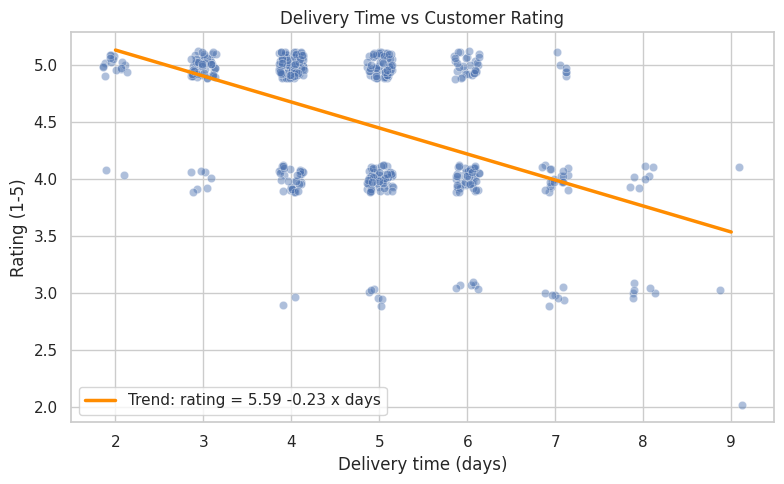

In [35]:
pair = df[["delivery_days", "rating"]].dropna()
jit = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(x=pair["delivery_days"] + jit.uniform(-0.15, 0.15, len(pair)),
                y=pair["rating"] + jit.uniform(-0.12, 0.12, len(pair)),
                alpha=0.45, color=palette[0], ax=ax)
slope, intercept = np.polyfit(pair["delivery_days"], pair["rating"], 1)
xs = np.array([pair["delivery_days"].min(), pair["delivery_days"].max()])
ax.plot(xs, intercept + slope * xs, color="darkorange", linewidth=2.5,
        label=f"Trend: rating = {intercept:.2f} {slope:+.2f} x days")
ax.set(title="Delivery Time vs Customer Rating", xlabel="Delivery time (days)", ylabel="Rating (1-5)")
ax.legend()
save_fig("06_scatter_delivery_vs_rating")
plt.show()

**Observation.** The points drift downward from left to right: slower deliveries receive lower ratings. The fitted line has a slope of **-0.23**, meaning each extra delivery day is associated with about **0.23 fewer rating points** on average (Pearson r = **-0.51**, based on 460 orders that have both values). This is an association, not proof that delivery time *causes* low ratings.

### Chart 7 – Bar chart with error bars (Seaborn): average rating by delivery speed

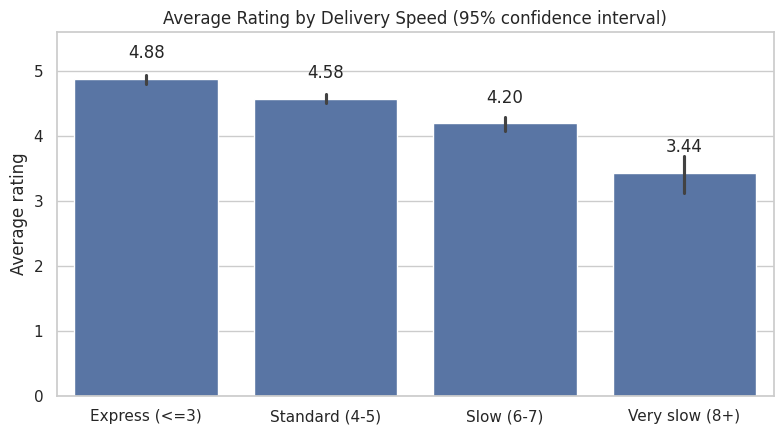

In [36]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=df, x="delivery_speed", y="rating", errorbar=("ci", 95), color=palette[0], ax=ax)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=12)
ax.set(title="Average Rating by Delivery Speed (95% confidence interval)", xlabel="", ylabel="Average rating", ylim=(0, 5.6))
save_fig("07_bar_rating_by_delivery_speed")
plt.show()

**Observation.** The average rating falls steadily as delivery gets slower: from **4.88** for the fastest group to **3.44** for the slowest. The vertical lines on each bar show the 95% confidence interval; groups with few orders (such as the slowest) have wider bars, meaning less certainty about their true average.

### Chart 8 – Box plot (Seaborn): delivery time by region

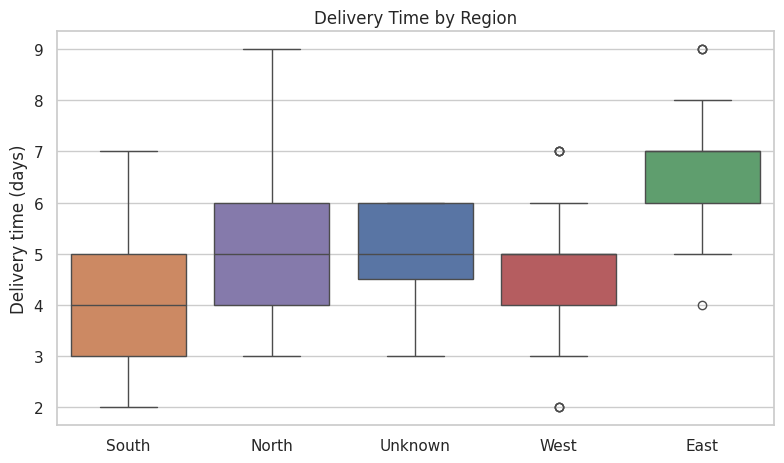

In [37]:
region_order = df.groupby("region")["delivery_days"].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.boxplot(data=df, x="region", y="delivery_days", order=region_order, hue="region", legend=False, ax=ax)
ax.set(title="Delivery Time by Region", xlabel="", ylabel="Delivery time (days)")
save_fig("08_box_delivery_by_region")
plt.show()

**Observation.** Regions are ordered from fastest to slowest median delivery time: **South (4), North (5), Unknown (5), West (5), East (7)** days. In each box the line is the median, the box covers the middle 50% of orders and the dots are unusual values. (The `Unknown` group contains only 7 orders, so its box is based on very little data.) Box plots compare both the **centre and the spread** of several groups at once, which a table of averages cannot do.

### Chart 9 – Box plot on a log scale: order revenue by category

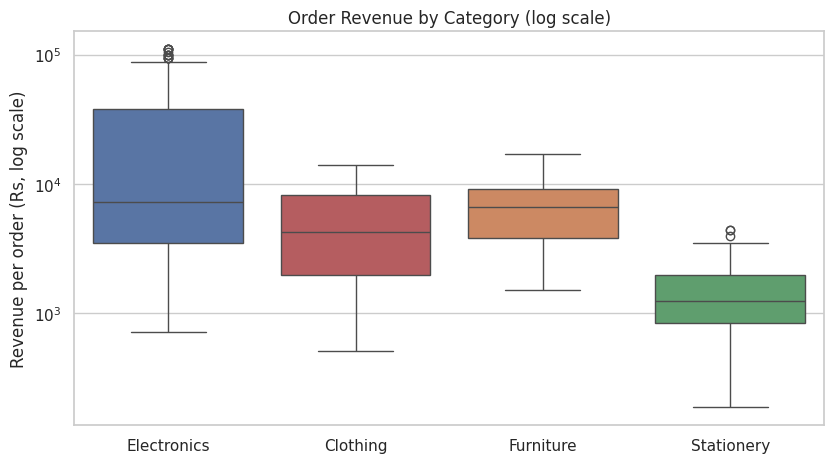

In [38]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
cat_order = cat_summary.index
sns.boxplot(data=df[df["revenue"] > 0], x="category", y="revenue", order=cat_order, hue="category", legend=False, ax=ax)
ax.set_yscale("log")
ax.set(title="Order Revenue by Category (log scale)", xlabel="", ylabel="Revenue per order (Rs, log scale)")
save_fig("09_box_revenue_by_category")
plt.show()

**Observation.** Revenue per order varies greatly between categories: the median ranges from Rs 1,245 (**Stationery**) to Rs 7,199 (**Electronics**), and the spread inside a category can be larger still. A **log scale** is used because on a normal axis the cheaper categories would be squashed flat next to the highest-priced orders. The box is widest for **Electronics**, because it mixes cheap and expensive products.

### Chart 10 – Heat map (Seaborn): correlation matrix

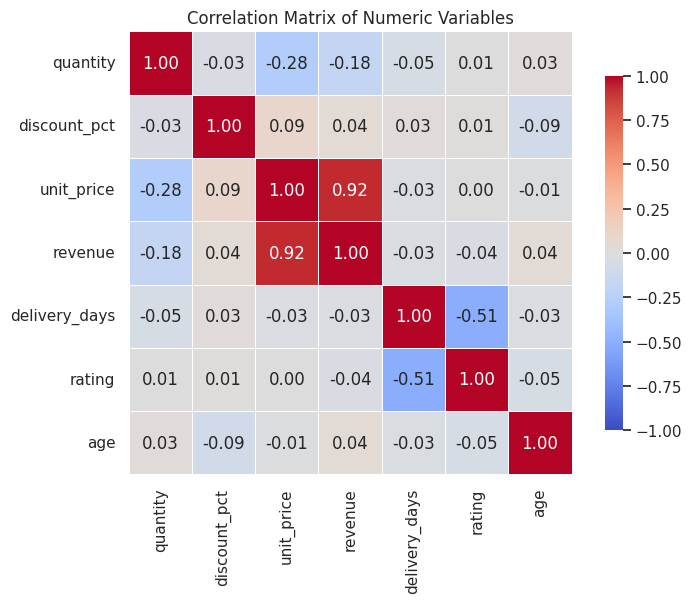

In [39]:
num_cols = ["quantity", "discount_pct", "unit_price", "revenue", "delivery_days", "rating", "age"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation Matrix of Numeric Variables")
save_fig("10_heatmap_correlation")
plt.show()

In [40]:
# Rank the strongest pairs (each pair listed once)
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename("r").to_frame()
pairs["abs_r"] = pairs["r"].abs()
top_pairs = pairs.sort_values("abs_r", ascending=False).head(5)[["r"]]
top_pairs

r
unit_price    revenue     0.92
delivery_days rating     -0.51
quantity      unit_price -0.28
              revenue    -0.18
discount_pct  age        -0.09

**Observation.** The strongest relationships are shown in the table above: **unit_price and revenue** (r = 0.92) is the strongest, and **delivery_days and rating** (r = -0.51) is second. Some strong pairs are partly **built in** by definition (revenue is computed from quantity, price and discount), so they should not be reported as discoveries. The relationship between delivery time and rating (r = -0.51) is a genuine behavioural pattern worth investigating. Values near 0 (for example age) indicate no linear relationship.

### Chart 11 – Heat map (Seaborn): net revenue by region and category

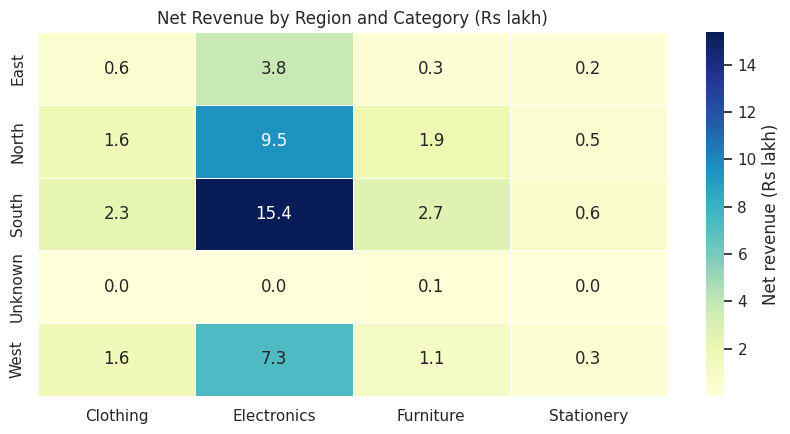

In [41]:
heat = pivot.drop(index="Total", columns="Total")          # remove the margin totals
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5, cbar_kws={"label": "Net revenue (Rs lakh)"}, ax=ax)
ax.set(title="Net Revenue by Region and Category (Rs lakh)", xlabel="", ylabel="")
save_fig("11_heatmap_region_category")
plt.show()

**Observation.** The darkest cell is **South / Electronics** (15.4 lakh), so that combination is the largest single revenue pocket. Colour intensity makes a 5 x 4 table of numbers readable at a glance. Regions with fewer customers naturally show lighter cells, so this chart shows *where revenue comes from*, not which region performs best per customer.

### Chart 12 – Stacked bar chart (Pandas plotting): order outcome by category

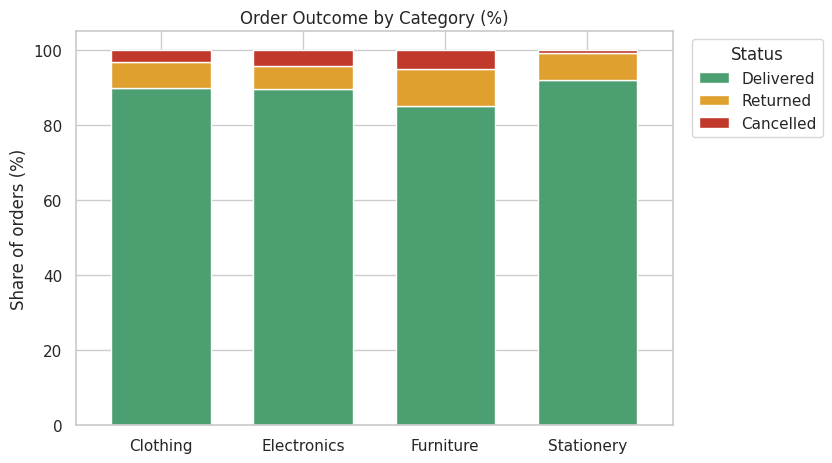

In [42]:
status_pct = pd.crosstab(df["category"], df["order_status"], normalize="index").mul(100)[["Delivered", "Returned", "Cancelled"]]
ax = status_pct.plot(kind="bar", stacked=True, figsize=(8.5, 4.8), color=["#4c9f70", "#e0a030", "#c0392b"], width=0.7)
ax.set(title="Order Outcome by Category (%)", xlabel="", ylabel="Share of orders (%)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Status", bbox_to_anchor=(1.02, 1), loc="upper left")
save_fig("12_stacked_status_by_category")
plt.show()

**Observation.** Most orders in every category are delivered (**85.0% to 92.0%**). The highest share of returned or cancelled orders is in **Furniture** (**15.0%**). Because each category has only 100 to 164 orders, these percentages move noticeably with a handful of orders, so differences between categories should be treated cautiously.

In [43]:
print("Figures saved in outputs/figures/:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("  ", p.name)

Figures saved in outputs/figures/:
   01_bar_revenue_by_category.png
   02_count_payment_method.png
   03_line_monthly_revenue.png
   04_hist_delivery_days.png
   05_hist_revenue_raw_vs_log.png
   06_scatter_delivery_vs_rating.png
   07_bar_rating_by_delivery_speed.png
   08_box_delivery_by_region.png
   09_box_revenue_by_category.png
   10_heatmap_correlation.png
   11_heatmap_region_category.png
   12_stacked_status_by_category.png


---
# 7. Basic Data Analysis

### Exercise 7.1 – Descriptive statistics

In [44]:
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc["cv_%"] = desc["std"] / desc["mean"] * 100          # coefficient of variation: spread relative to the mean
display(desc[["count", "mean", "50%", "std", "min", "max", "skew", "cv_%"]])

print("Share of orders (%) by category-type columns:")
for col in ["order_status", "segment", "region"]:
    print(f"\n{col}:")
    print(df[col].value_counts(normalize=True).mul(100).round(1).to_string())

,count,mean,50%,std,min,max,skew,cv_%
quantity,517.00,2.48,2.00,1.73,1.00,8.00,1.52,69.81
discount_pct,517.00,6.76,5.00,6.88,0.00,20.00,0.59,101.82
unit_price,517.00,"7,476.76","2,499.00","14,245.81",199.00,"54,999.00",2.79,190.53
revenue,517.00,"10,761.44","3,909.15","19,647.32",189.05,"109,998.00",3.38,182.57
delivery_days,492.00,4.82,5.00,1.38,2.00,9.00,0.31,28.56
rating,484.00,4.50,5.00,0.62,2.00,5.00,-0.90,13.75
age,464.00,42.82,44.00,13.55,19.00,63.00,-0.14,31.65


Share of orders (%) by category-type columns:

order_status:
order_status
Delivered   89.40
Returned     7.40
Cancelled    3.30

segment:
segment
Consumer      53.80
Corporate     24.40
Home Office   20.50
Unknown        1.40

region:
region
South     36.60
North     29.80
West      23.60
East       8.70
Unknown    1.40


**Observation.**
- The average order is worth Rs 10,761 but the median is only Rs 3,909: the mean is pulled up by a few very large orders (skewness 3.38). For skewed variables the **median describes a typical order better than the mean**.
- `unit_price` has the largest coefficient of variation (**191%**), so it is the most unequal variable, while `rating` varies least (**14%**). Ratings average 4.50 out of 5.
- Delivery time averages 4.82 days with a standard deviation of 1.38; **89.4%** of orders were delivered successfully.

### Exercise 7.2 – Distributions

In [45]:
for col in ["delivery_days", "rating", "revenue", "quantity", "age"]:
    s = df[col].dropna()
    gap = (s.mean() - s.median()) / s.std()
    shape = "roughly symmetric" if abs(s.skew()) < 0.5 else ("right-skewed (long tail of high values)" if s.skew() > 0 else "left-skewed (long tail of low values)")
    print(f"{col:<14} mean={s.mean():>9,.2f}  median={s.median():>9,.2f}  skew={s.skew():>5.2f}  -> {shape}")

print("\nRating distribution (% of rated orders):")
print(df["rating"].value_counts(normalize=True).sort_index().mul(100).round(1).to_string())

delivery_days  mean=     4.82  median=     5.00  skew= 0.31  -> roughly symmetric
rating         mean=     4.50  median=     5.00  skew=-0.90  -> left-skewed (long tail of low values)
revenue        mean=10,761.44  median= 3,909.15  skew= 3.38  -> right-skewed (long tail of high values)
quantity       mean=     2.48  median=     2.00  skew= 1.52  -> right-skewed (long tail of high values)
age            mean=    42.82  median=    44.00  skew=-0.14  -> roughly symmetric

Rating distribution (% of rated orders):
rating
2.00    0.20
3.00    6.00
4.00   37.20
5.00   56.60


**Observation.** Each variable has a different shape. **Delivery time** and **age** are close to symmetric, **revenue** and **quantity** are right-skewed (many small values, few large ones), and **rating** is left-skewed: **93.8%** of rated orders received 4 or 5 stars. Knowing the shape matters: symmetric variables can be summarized with the mean, skewed ones with the median, and strongly skewed ones may need a log transform before modelling.

### Exercise 7.3 – Relationships between variables

In [46]:
from scipy import stats

pair = df[["delivery_days", "rating"]].dropna()
r_p, p_p = stats.pearsonr(pair["delivery_days"], pair["rating"])
r_s, p_s = stats.spearmanr(pair["delivery_days"], pair["rating"])
print(f"Delivery time vs rating  (n = {len(pair)})")
print(f"  Pearson  r = {r_p:.3f}   (p-value {p_p:.1e})")
print(f"  Spearman r = {r_s:.3f}   (p-value {p_s:.1e})")

print("\nAverage rating by delivery-speed group:")
by_speed = df.groupby("delivery_speed", observed=True)["rating"].agg(["count", "mean"]).rename(columns={"count": "rated_orders", "mean": "avg_rating"})
display(by_speed)

print("Other relationships (Pearson r):")
print(f"  discount vs quantity       : {df['discount_pct'].corr(df['quantity']):.3f}")
print(f"  unit price vs quantity     : {df['unit_price'].corr(df['quantity']):.3f}")
print(f"  log(unit price) vs quantity: {np.log(df['unit_price']).corr(df['quantity']):.3f}")
print(f"  age vs revenue             : {df['age'].corr(df['revenue']):.3f}")

Delivery time vs rating  (n = 460)
  Pearson  r = -0.510   (p-value 8.6e-32)
  Spearman r = -0.486   (p-value 1.2e-28)

Average rating by delivery-speed group:


,rated_orders,avg_rating
delivery_speed,,
Express (<=3),76,4.88
Standard (4-5),252,4.58
Slow (6-7),116,4.20
Very slow (8+),16,3.44


Other relationships (Pearson r):
  discount vs quantity       : -0.033
  unit price vs quantity     : -0.280
  log(unit price) vs quantity: -0.562
  age vs revenue             : 0.041


**Observation.**
- **Delivery time and rating** have a clear negative relationship (Pearson r = **-0.51**, Spearman = **-0.49**). Both agree, which suggests the relationship is not driven by a few extreme points. The p-values are extremely small, so a pattern this strong is very unlikely to appear by chance in 460 orders. (Statistical significance says the pattern is *real in this sample*; it does not say *why* it exists.)
- **Discount and quantity** are essentially unrelated (r = -0.03): giving bigger discounts did not make customers buy more units in this data.
- **Price and quantity** are negatively related (r = -0.28): customers buy fewer units of expensive products, which is common sense.
- **Age and revenue** show no meaningful relationship (r = 0.04).

### Exercise 7.4 – Looking for patterns

In [47]:
total_net = df["net_revenue"].sum()
q4_share = df.loc[df["quarter"] == "Q4", "net_revenue"].sum() / total_net * 100
print(f"Q4 share of annual net revenue: {q4_share:.1f}%  (equal quarters would be 25%)")

print("\nNet revenue and average order value by quarter:")
qtr_summary = df.groupby("quarter").agg(orders=("order_id", "count"), net_revenue=("net_revenue", "sum"), avg_order_value=("revenue", "mean"))
display(qtr_summary)

print("Return/cancel rate (%) by payment method:")
print(df.groupby("payment_method", observed=True)["is_problem_order"].mean().mul(100).round(1).sort_values(ascending=False).to_string())

print("\nAverage order value (Rs) by customer segment:")
print(df.groupby("segment")["revenue"].mean().round(0).sort_values(ascending=False).to_string())

print("\nShare of net revenue from the top 10% of orders:")
top10 = df["net_revenue"].nlargest(int(len(df) * 0.10)).sum() / total_net * 100
print(f"  {top10:.1f}%")

Q4 share of annual net revenue: 34.8%  (equal quarters would be 25%)

Net revenue and average order value by quarter:


,orders,net_revenue,avg_order_value
quarter,,,
Q1,114,"979,779.15","8,885.37"
Q2,109,"914,334.10","9,831.75"
Q3,114,"1,354,935.75","13,746.36"
Q4,180,"1,732,167.90","10,622.16"


Return/cancel rate (%) by payment method:
payment_method
Debit Card    15.00
Credit Card   10.70
UPI           10.20
Cash           4.80

Average order value (Rs) by customer segment:
segment
Consumer      12,521.00
Home Office    9,383.00
Corporate      8,404.00
Unknown        4,207.00

Share of net revenue from the top 10% of orders:
  60.3%


**Observation.**
- **Seasonality:** Q4 has the most orders (**180** against 109 to 114 in the other quarters) and **34.8%** of annual net revenue, compared with 25% if sales were even. Q3 has the highest average order value, which shows that revenue also depends on *what* is sold, not only on how many orders arrive.
- **Concentration:** the top 10% of orders generate **60.3%** of net revenue. Revenue depends heavily on a few large purchases, so losing a handful of big orders would hurt much more than losing many small ones.
- **Returns by payment method** range from 4.8% to 15.0%. Each method has only 63 to 197 orders, and differences of a few percentage points on groups this small can easily be chance, so no conclusion is drawn.
- **Customer segments:** average order value ranges from Rs 4,207 (Unknown) to Rs 12,521 (Consumer). Because order values are so skewed, such gaps could be caused by a few large orders and should be checked on more data before acting on them.

### Exercise 7.5 – A first machine-learning step with Scikit-learn
*Question: can delivery time alone predict a customer's rating?* A simple linear regression is fitted on a training set and judged on **unseen** test data, compared with a naive baseline that always predicts the average rating.

In [48]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler

model_df = df[["delivery_days", "rating"]].dropna()
X, y = model_df[["delivery_days"]], model_df["rating"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED)
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
baseline = np.full(len(y_test), y_train.mean())          # naive model: always predict the training average

print(f"\nModel: rating = {model.intercept_:.2f} + ({model.coef_[0]:.2f}) x delivery_days")
print(f"Test R-squared          : {r2_score(y_test, pred):.3f}")
print(f"Test MAE (model)        : {mean_absolute_error(y_test, pred):.3f} rating points")
print(f"Test MAE (baseline mean): {mean_absolute_error(y_test, baseline):.3f} rating points")

# Feature scaling with StandardScaler (needed by many other algorithms)
scaler = StandardScaler().fit(X_train)
scaled = scaler.transform(X_train)
print(f"\nScaled training feature: mean = {scaled.mean():.3f}, std = {scaled.std():.3f}")
print("Predicted rating for a 3-day delivery :", model.predict(pd.DataFrame({"delivery_days": [3]}))[0].round(2))
print("Predicted rating for a 9-day delivery :", model.predict(pd.DataFrame({"delivery_days": [9]}))[0].round(2))

Training rows: 345 | Test rows: 115

Model: rating = 5.65 + (-0.24) x delivery_days
Test R-squared          : 0.133
Test MAE (model)        : 0.448 rating points
Test MAE (baseline mean): 0.535 rating points

Scaled training feature: mean = 0.000, std = 1.000
Predicted rating for a 3-day delivery : 4.92
Predicted rating for a 9-day delivery : 3.45


**Observation.** On data the model had never seen, the regression explains **13%** of the variation in ratings (R-squared = 0.13). Its average error is **0.45** rating points compared with **0.53** for the naive "always predict the average" baseline, an improvement of about **16%**. That is a modest but real gain: delivery time carries useful information about satisfaction, yet most of the variation in ratings is left unexplained, because many other factors (product quality, price, packaging) are not in the model and ratings are whole numbers capped at 5. The fitted line says each additional delivery day lowers the predicted rating by about **0.24** points.

This is an **exploratory** model: ratings are whole numbers, only one predictor is used and the data is synthetic, so it demonstrates the *workflow* (split, fit, evaluate against a baseline, scale) rather than a production-ready predictor.

### Exercise 7.6 – Initial observations from the analysis

In [49]:
obs = pd.Series({
    "Orders analysed (after cleaning)": f"{len(df)}",
    "Net revenue (delivered orders)": f"Rs {total_net:,.0f}",
    "Top category by net revenue": f"{cat_summary.index[0]} ({cat_summary['revenue_share_%'].iloc[0]:.1f}%)",
    "Highest-revenue month": month_labels[int(monthly['net_revenue'].idxmax()) - 1],
    "Q4 share of net revenue": f"{q4_share:.1f}%",
    "Average delivery time": f"{df['delivery_days'].mean():.2f} days",
    "Fastest / slowest region": f"{region_summary.index[0]} / {region_summary.drop('Unknown', errors='ignore').index[-1]}",
    "Average rating": f"{df['rating'].mean():.2f} / 5",
    "Delivery time vs rating (Pearson r)": f"{r_p:.2f}",
    "Return + cancel rate": f"{df['is_problem_order'].mean() * 100:.1f}%",
}, name="Result").to_frame()
obs

,Result
Orders analysed (after cleaning),517
Net revenue (delivered orders),"Rs 4,981,217"
Top category by net revenue,Electronics (72.2%)
Highest-revenue month,Sep
Q4 share of net revenue,34.8%
Average delivery time,4.82 days
Fastest / slowest region,South / East
Average rating,4.50 / 5
Delivery time vs rating (Pearson r),-0.51
Return + cancel rate,10.6%


---
# 8. Key Insights, Limitations and Recommendations

## 8.1 Key insights
1. **Data quality came first.** The raw files contained duplicates, text in numeric columns, 14 spellings of 4 payment methods, impossible values and an orphan customer ID. Left untreated they would have caused wrong totals (for example **13 UPI orders** missed by a simple filter) and double-counted sales.
2. **Revenue is driven by high-priced products and a few large orders.** Electronics earns 72.2% of net revenue, and the top 10% of orders bring in 60.3%.
3. **The year-end quarter is the busiest.** Q4 has the most orders and 34.8% of net revenue, though monthly revenue is volatile because a few expensive orders can swing a month.
4. **Delivery speed and satisfaction move together.** Slower deliveries get lower ratings (r = -0.51), and the regions differ in delivery time, so logistics could be a lever for customer satisfaction.
5. **Discounts did not visibly increase the units bought** (r = -0.03), so it may be worth testing whether smaller discounts would cost less without reducing sales.

## 8.2 Limitations
- **The dataset is synthetic.** The patterns were partly built in when the data was generated (for example the link between region, delivery time and rating), so they illustrate the methods and should not be read as real business findings.
- **Sample size.** With about 500 orders, group-level percentages (for example returns by payment method) are unstable.
- **Assumptions in cleaning.** Missing discounts were treated as 0% and missing quantities were filled with category medians; both are reasonable but unverified assumptions.
- **Association is not causation.** A correlation between delivery time and rating does not prove that faster delivery *causes* better ratings.
- **Simple model.** The regression uses one variable and was meant to demonstrate the workflow only.

## 8.3 Recommendations (if this were real data)
- Validate data **at entry** (drop-down menus for payment method, numeric fields for delivery time) so the quality problems found here do not occur.
- Investigate the slower regions and delivery-time delays, because they are linked with lower ratings.
- Plan stock and staffing for the busy final quarter, and review whether the current discounts are worth their cost.
- Collect more data and test the findings with a larger sample before making decisions.

---
# 9. Conclusion and Reproducibility

## 9.1 Objectives checklist
| # | Objective | Status | Evidence in this notebook |
|---|---|---|---|
| 1 | Set up the Data Science environment | Done | Section 1: installation steps, version check, imports and configuration |
| 2 | Work with data using Pandas & NumPy | Done | Sections 2, 3, 5: arrays, vectorization, selection, filtering, sorting, grouping, aggregation, merging, transformation |
| 3 | Perform data cleaning | Done | Section 4: duplicates, inconsistent text, data types, invalid values, outliers, missing values, validation checks |
| 4 | Create data visualizations | Done | Section 6: 12 charts (bar, line, histogram, scatter, box, heat map, stacked bar) saved in `outputs/figures/` |
| 5 | Perform basic data analysis | Done | Section 7: descriptive statistics, distributions, correlations, patterns, a first Scikit-learn model |
| 6 | Document practical exercises | Done | Every exercise has code, output and an observation; Sections 8-9 summarize insights |

## 9.2 Reproducibility checklist
- **Fixed random seed** (`SEED = 42`) for both the data generator and the notebook.
- **Relative paths** only; raw data is read-only and cleaned data is saved separately in `data/processed/`.
- **`requirements.txt`** lists the libraries; **`src/generate_data.py`** recreates the raw data exactly.
- **Validation checks** (`assert` statements) stop the notebook if the cleaned data breaks a rule.
- To reproduce: install the requirements, open the notebook and choose **Kernel → Restart & Run All**.

## 9.3 Conclusion
This lab covered the full beginner Data Science workflow: preparing the environment, practising NumPy and Pandas, auditing and cleaning a messy dataset, visualizing it with Matplotlib and Seaborn, and extracting first insights with descriptive statistics, correlation and a simple Scikit-learn model. The main lesson is that **trustworthy analysis depends on the order of the steps**: the data must be audited and cleaned before it is summarized, and every number should be interpreted with its limitations in mind.

**Next steps:** repeat the workflow on a real public dataset, test hypotheses formally (t-tests, ANOVA), build multi-variable regression and classification models with cross-validation, and build an interactive dashboard.